# NARDINI+ from a `Protein` object

NARDINI asks a simple question: **are the residues in this IDR arranged non-randomly?**
It answers it by comparing the sequence against thousands of scrambles of *itself*, so the
answer is independent of composition by construction. NARDINI+ adds a second block of
features describing the composition itself, scored against a reference set of IDRs.

This notebook covers the single-sequence interface, reached through `Protein.nardini`.
If you have a whole set of sequences, or you want to build your own compositional
background, see the companion notebook `nardini_module.ipynb`.

**What you get**

| | features | compared against | needs a background? |
|---|---|---|---|
| patterning | 36 | scrambles of the sequence itself | no |
| compositional | 54 | a reference set of IDRs | yes |

A positive patterning z-score means a residue type (or pair of types) is **more segregated
— blockier — than the sequence's own composition predicts**. Negative means **more evenly
interspersed** than expected. Both are relative to what a random arrangement of the same
residues would look like.

In [1]:
import numpy as np
from matplotlib import pyplot as plt

from sparrow import Protein

%matplotlib inline

## Getting an IDR to work with

NARDINI is designed for disordered regions, so the first step in a real analysis is
usually to find them. We will use human BARD1 (UniProt Q99728) and let sparrow's
disorder predictor mark the boundaries.

In [2]:
BARD1_sequence = (
    "MPDNRQPRNRQPRIRSGNEPRSAPAMEPDGRGAWAHSRAALDRLEKLLRCSRCTNILREPVCLGGCEHIFCSNCVSDCIGT"
    "GCPVCYTPAWIQDLKINRQLDSMIQLCSKLRNLLHDNELSDLKEDKPRKSLFNDAGNKKNSIKMWFSPRSKKVRYVVSKAS"
    "VQTQPAIKKDASAQQDSYEFVSPSPPADVSERAKKASARSGKKQKKKTLAEINQKWNLEAEKEDGEFDSKEESKQKLVSFC"
    "SQPSVISSPQINGEIDLLASGSLTESECFGSLTEVSLPLAEQIESPDTKSRNEVVTPEKVCKNYLTSKKSLPLENNGKRGH"
    "HNRLSSPISKRCRTSILSTSGDFVKQTVPSENIPLPECSSPPSCKRKVGGTSGRKNSNMSDEFISLSPGTPPSTLSSSSYR"
    "RVMSSPSAMKLLPNMAVKRNHRGETLLHIASIKGDIPSVEYLLQNGSDPNVKDHAGWTPLHEACNHGHLKVVELLLQHKAL"
    "VNTTGYQNDSPLHDAAKNGHVDIVKLLLSYGASRNAVNIFGLRPVDYTDDESMKSLLLLPEKNESSSASHCSVMNTGQRRD"
    "GPLVLIGSGLSSEQQKMLSELAVILKAKKYTEFDSTVTHVVVPGDAVQSTLKCMLGILNGCWILKFEWVKACLRRKVCEQE"
    "EKYEIPEGPRRSRLNREQLLPKLFDGCYFYLWGTFKHHPKDNLIKLVTAGGGQILSRKPKPDSDVTQTINTVAYHARPDSD"
    "QRFCTQYIIYEDLCNYHPERVRQGKVWKAPSSWFIDCVMSFELLPLDS"
)

BARD1 = Protein(BARD1_sequence)
boundaries = BARD1.predictor.disorder_domains(return_boundaries=True)

print(f"BARD1 is {len(BARD1)} residues, with {len(boundaries)} predicted IDRs:")
for start, end in boundaries:
    print(f"  {start:4d}-{end:4d}  ({end - start:3d} residues)")

BARD1 is 777 residues, with 3 predicted IDRs:
     0-  38  ( 38 residues)
   117- 419  (302 residues)
   543- 563  ( 20 residues)


The long central region is the interesting one. We make a new `Protein` from just that
slice — NARDINI should be run on the IDR, not on the whole protein, since folded domains
have their own quite different statistics.

In [3]:
start, end = boundaries[1]
idr = Protein(BARD1_sequence[start:end])

print(f"BARD1 IDR {start}-{end}, {len(idr)} residues")
print(idr.sequence)

BARD1 IDR 117-419, 302 residues
NELSDLKEDKPRKSLFNDAGNKKNSIKMWFSPRSKKVRYVVSKASVQTQPAIKKDASAQQDSYEFVSPSPPADVSERAKKASARSGKKQKKKTLAEINQKWNLEAEKEDGEFDSKEESKQKLVSFCSQPSVISSPQINGEIDLLASGSLTESECFGSLTEVSLPLAEQIESPDTKSRNEVVTPEKVCKNYLTSKKSLPLENNGKRGHHNRLSSPISKRCRTSILSTSGDFVKQTVPSENIPLPECSSPPSCKRKVGGTSGRKNSNMSDEFISLSPGTPPSTLSSSSYRRVMSSPSAMKLLPN


## The patterning half

`patterning()` needs no reference data at all — the null distribution comes from scrambling
this sequence. `num_scrambles` controls how many; the default is 10,000, and the published
protocol uses 100,000. Pass a `seed` if you want the numbers to be reproducible.

In [4]:
patterning = idr.nardini.patterning(seed=42)
patterning

FeatureVector 'patterning'|36 features

What comes back is a `FeatureVector`: a plain NumPy array with the feature names kept
alongside it, so you can address a feature by name instead of remembering an index.
Patterning features are named `'<type>-<type>'` for the eight residue types.

In [5]:
print("value by name        :", round(patterning["pol-neg"], 3))
print("the underlying array :", type(patterning.values), patterning.values.shape)
print("the matching labels  :", patterning.names[:4], "...")
print("as a dict            :", list(patterning.to_dict().items())[:2], "...")
print("length / membership  :", len(patterning), "|", "pol-neg" in patterning)

value by name        : 0.751
the underlying array : <class 'numpy.ndarray'> (36,)
the matching labels  : ('pol-pol', 'pol-hyd', 'pol-pos', 'pol-neg') ...
as a dict            : [('pol-pol', -0.8985171410530924), ('pol-hyd', -1.7471153074056067)] ...
length / membership  : 36 | True


The eight types are groups of chemically similar residues, so `pol-neg` is
"polar residues versus negatively charged residues". A feature with the same type twice
(`pos-pos`) describes how clustered that one type is with itself.

In [6]:
from sparrow.nardini import get_typeset

for name, residues in get_typeset("8").items():
    print(f"  {name:5s} {''.join(sorted(residues))}")

print()
print("36 features = the 8 types plus every pair of them:")
print(", ".join(patterning.names))

  pol   CHNQST
  hyd   ILMV
  pos   KR
  neg   DE
  aro   FWY
  ala   A
  pro   P
  gly   G

36 features = the 8 types plus every pair of them:
pol-pol, pol-hyd, pol-pos, pol-neg, pol-aro, pol-ala, pol-pro, pol-gly, hyd-hyd, hyd-pos, hyd-neg, hyd-aro, hyd-ala, hyd-pro, hyd-gly, pos-pos, pos-neg, pos-aro, pos-ala, pos-pro, pos-gly, neg-neg, neg-aro, neg-ala, neg-pro, neg-gly, aro-aro, aro-ala, aro-pro, aro-gly, ala-ala, ala-pro, ala-gly, pro-pro, pro-gly, gly-gly


A 9-type scheme is also available via `typeset='9'`, which splits the polar group and gives
45 patterning features instead.

### Which features are most non-random?

There is no special method for this — `.values` is a normal array, so use NumPy.

In [7]:
order = np.argsort(-np.abs(patterning.values))
print("feature      z-score")
for index in order[:8]:
    print(f"  {patterning.names[index]:10s}  {patterning.values[index]:+7.2f}")

feature      z-score
  pos-pos       +3.02
  pos-neg       +2.94
  neg-neg       +1.82
  pol-hyd       -1.75
  hyd-pos       +1.26
  pol-pol       -0.90
  hyd-hyd       -0.81
  pol-neg       +0.75


The strongest signals here are `pos-pos` and `pos-neg`: the positively charged residues in
this IDR are clustered together far more than a random arrangement of the same residues
would be, and they are also segregated from the negatively charged ones. Reading the
sequence above, that is the `KKASARSGKKQKKK` stretch and its neighbours — NARDINI has
recovered it without being told anything about charge.

Note that only 10 of the 36 features are non-zero. That is not an error; see below.

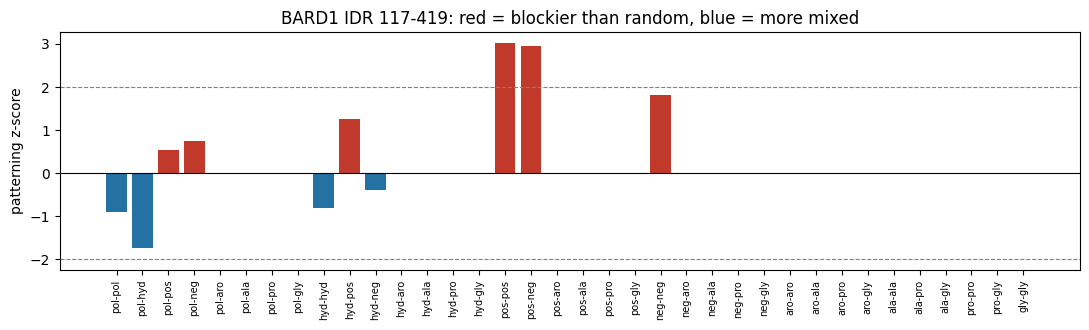

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.4))

colors = ["#c0392b" if z > 0 else "#2471a3" for z in patterning.values]
ax.bar(range(len(patterning)), patterning.values, color=colors)
ax.axhline(0, color="black", lw=0.8)
for level in (-2, 2):
    ax.axhline(level, color="grey", ls="--", lw=0.8)

ax.set_xticks(range(len(patterning)))
ax.set_xticklabels(patterning.names, rotation=90, fontsize=7)
ax.set_ylabel("patterning z-score")
ax.set_title(f"BARD1 IDR {start}-{end}: red = blockier than random, blue = more mixed")
plt.tight_layout()
plt.show()

### Why some features are exactly zero

A z-score of exactly `0.0` means **the feature was not scored**, not "perfectly random".
A pair of residue types is only evaluated if both are abundant enough to say anything
about — controlled by `min_fraction`, default 0.10. Lower it to score more pairs, at the
cost of z-scores computed from very few residues.

In [9]:
default = idr.nardini.patterning(seed=42)
permissive = idr.nardini.patterning(seed=42, min_fraction=0.02)

print(f"min_fraction=0.10 : {np.count_nonzero(default.values):2d} of 36 features scored")
print(f"min_fraction=0.02 : {np.count_nonzero(permissive.values):2d} of 36 features scored")

min_fraction=0.10 : 10 of 36 features scored
min_fraction=0.02 : 36 of 36 features scored


## The compositional half

These 54 features are z-scored against a **reference set of IDRs**, so unlike the
patterning half they are only as meaningful as the background behind them. For a single
protein there is nothing sensible to build a background from, so sparrow defaults to the
published human IDRome background that ships with it.

In [10]:
composition_z = idr.nardini.composition()
composition_raw = idr.nardini.composition(raw=True)

print("feature            raw     z (vs human IDRome)")
for name in ["FCR", "NCPR", "Frac S", "Frac P", "Frac K+R", "Hydrophobicity"]:
    print(f"  {name:16s} {composition_raw[name]:6.3f}   {composition_z[name]:+7.2f}")

feature            raw     z (vs human IDRome)
  FCR               0.278     +0.09
  NCPR              0.046     +0.53
  Frac S            0.175     +0.76
  Frac P            0.076     -0.52
  Frac K+R          0.162     +0.47
  Hydrophobicity    3.663     +0.55


Positive means enriched relative to the reference. Because the reference *is* the human
IDRome and this *is* a human IDR, most of these sit within a couple of standard
deviations — which is exactly what you would hope.

You can score against a different species instead. Nine published IDRomes are bundled.

In [11]:
from sparrow.nardini import REFERENCE_SPECIES

print("bundled backgrounds:", ", ".join(sorted(REFERENCE_SPECIES)))
print()
for species in ["human", "yeast", "arabidopsis"]:
    z = idr.nardini.composition(background=species)
    print(f"  vs {species:12s} Frac S = {z['Frac S']:+6.2f}   Frac K+R = {z['Frac K+R']:+6.2f}")

bundled backgrounds: arabidopsis, fly, human, mouse, rat, worm, xenopus, yeast, zebrafish

  vs human        Frac S =  +0.76   Frac K+R =  +0.47
  vs yeast        Frac S =  +0.35   Frac K+R =  +0.40
  vs arabidopsis  Frac S =  +0.38   Frac K+R =  +0.29


### These are ordinary Protein properties too

Most of the compositional features are not NARDINI-specific — they are plain
sequence properties, and they are available directly on the `Protein` without
computing a vector at all. There is one implementation behind both, so the numbers
are identical rather than merely similar.

In [12]:
pairs = [
    ("FCR", idr.FCR),
    ("NCPR", idr.NCPR),
    ("Hydrophobicity", idr.hydrophobicity),
    ("Frac Aromatic", idr.fraction_aromatic),
    ("Iso point", idr.isoelectric_point),
    ("PPII", idr.PPII_propensity),
    ("Frac Chain Expanding", idr.fraction_chain_expanding),
    ("Disorder Promoting", idr.fraction_disorder_promoting),
    ("R/K Ratio", idr.RK_ratio),
]

print(f"{'NARDINI raw feature':22s} {'Protein property':>10s}   identical")
for name, value in pairs:
    print(f"  {name:20s} {value:10.4f}   {composition_raw[name] == value}")

NARDINI raw feature    Protein property   identical
  FCR                      0.2781   True
  NCPR                     0.0464   True
  Hydrophobicity           3.6626   True
  Frac Aromatic            0.0464   True
  Iso point                9.4062   True
  PPII                     0.3877   True
  Frac Chain Expanding     0.3543   True
  Disorder Promoting       0.7053   True
  R/K Ratio               -0.3802   True


The one deliberate exception is `Frac Polar`: NARDINI+ counts cysteine as polar and
`Protein.fraction_polar` does not, so the two differ by exactly the cysteine
content. Both conventions are used in the literature, and the published background
data is defined against the NARDINI one, so sparrow keeps them distinct rather than
silently reconciling them.

In [13]:
print("NARDINI 'Frac Polar' :", round(composition_raw["Frac Polar"], 4))
print("p.fraction_polar     :", round(idr.fraction_polar, 4))
print("difference           :", round(composition_raw["Frac Polar"] - idr.fraction_polar, 4))
print("cysteine fraction    :", round(composition_raw["Frac C"], 4))

NARDINI 'Frac Polar' : 0.3775
p.fraction_polar     : 0.3576
difference           : 0.0199
cysteine fraction    : 0.0199


So what does NARDINI+ add over reading those properties one by one? The
**z-scoring** — each value expressed relative to a reference set of IDRs, which is
what makes them comparable across sequences.

## The full 90-feature vector

`vector()` is the two halves concatenated — 36 patterning followed by 54 compositional.
This is the NARDINI+ vector, and the thing you would feed into clustering or a model.

In [14]:
v = idr.nardini.vector(seed=42)

print(v)
print()
print("patterning block :", v.values[:36].shape)
print("composition block:", v.values[36:].shape)
print()
print("both halves are addressable the same way:")
print("  v['pol-neg']  =", round(v["pol-neg"], 3), " (patterning)")
print("  v['Frac K+R'] =", round(v["Frac K+R"], 3), " (compositional)")

FeatureVector 'sequence'|90 features

patterning block : (36,)
composition block: (54,)

both halves are addressable the same way:
  v['pol-neg']  = 0.751  (patterning)
  v['Frac K+R'] = 0.47  (compositional)


Pass `background=None` to skip the compositional half entirely and get just the 36
patterning features — useful when you have no appropriate reference set.

In [15]:
print("with a background   :", len(idr.nardini.vector(seed=42)), "features")
print("background=None     :", len(idr.nardini.vector(background=None, seed=42)), "features")

with a background   : 90 features
background=None     : 36 features


## GIN cluster assignment

The GIN resource partitions the human IDRome into 30 clusters of shared molecular grammar,
each with a human-readable description. `gin_cluster()` computes this sequence's NARDINI+
vector and finds the nearest published centroid.

In [16]:
record = idr.nardini.gin_cluster(seed=42)

for key, value in record.items():
    print(f"  {key:20s} {value}")

  name                 sequence
  cluster              9
  description          Blocks of positive & negative residues
  distance             21.171729333694483
  separation           9.577148938725266
  n_saturated          1
  composition_rms_z    0.49404108290838145
  is_typical           True


`gin_report()` says the same thing in prose, including the runners-up and — importantly —
whether the label should be trusted at all.

In [17]:
print(idr.nardini.gin_report(seed=42))

GIN cluster 9: Blocks of positive & negative residues
  distance to centroid   21.17
  gap to runner-up       9.58
  saturated features     1 of 90
  composition RMS z      0.49   (~1 = typical of the reference IDRome)
  -> composition is consistent with the reference IDRome; the
     label is usable.
  nearest alternatives:
    25  Blocks of positive residues                   d=  30.75
    12  Blocks of positive, negative & polar residues d=  34.51
     4  Weak negative charge, high N fraction         d=  39.94


### When *not* to believe a GIN label

Nearest-centroid assignment never abstains. Every sequence gets a label, including one
that looks nothing like a human IDR. Three numbers on the record tell you when the label
is an extrapolation:

- **`separation`** — the gap to the runner-up cluster. Small means the sequence sits
  *between* two grammars, so the single label is arbitrary even if the sequence is
  otherwise perfectly ordinary.
- **`n_saturated`** — how many of the 90 features were pinned at the ±3 clip. A clipped
  feature contributes the same amount to every centroid distance, so it carries no
  information about *which* cluster is nearest.
- **`composition_rms_z`** — the most direct answer to "is this anything like a human IDR?".
  The 54 compositional features are z-scored against the reference IDRome, so a sequence
  drawn from that population has an RMS near 1. Real IDRs land at 0.6–0.9; a uniformly
  random sequence around 1.2–1.6 depending on the draw; homopolymers at 3–13.

`is_typical` combines these into a coarse screen. It is triage, not a statistical test.

Note that **distance to the nearest centroid is not a usable absolute measure** — in 90
dimensions even a perfectly ordinary z-vector sits about five times further from its
nearest centroid than the centroids sit from each other, because centroids are cluster
means rather than members. Compare distances between sequences, never against a threshold.

In [18]:
examples = {
    "BARD1 IDR": idr.sequence,
    "poly-Q (120)": "Q" * 120,
    "poly-E (120)": "E" * 120,
    "uniformly random": "".join(
        np.random.default_rng(0).choice(list("ACDEFGHIKLMNPQRSTVWY"), 150)
    ),
}

print(f"{'sequence':18s} {'cluster':46s} {'rms_z':>6s} {'sat':>4s} {'sep':>7s}  typical")
for label, sequence in examples.items():
    r = Protein(sequence).nardini.gin_cluster(seed=42, num_scrambles=2000)
    print(
        f"{label:18s} {r['description']:46s} {r['composition_rms_z']:6.2f} "
        f"{r['n_saturated']:4d} {r['separation']:7.2f}  {r['is_typical']}"
    )

sequence           cluster                                         rms_z  sat     sep  typical
BARD1 IDR          Blocks of positive & negative residues           0.49    0    9.67  True
poly-Q (120)       Q-tracts                                         4.95    7   36.41  False
poly-E (120)       D/E-tracts                                       3.78   11    3.07  False
uniformly random   Well-mixed hydrophobics, enriched in M           1.26    3    9.57  True


The homopolymer labels are semantically *correct* — poly-Q really is nearest to
`'Q-tracts'` — but `composition_rms_z` of 3+ says these sequences are nowhere near the
population the clusters were derived from, so the label is an extrapolation rather than a
membership claim. sparrow flags this rather than hiding it.

Note the poly-E row: its `separation` is small as well, so it does not even sit clearly
nearer `'D/E-tracts'` than to the runner-up. The uniformly random sequence, by contrast,
passes the screen — being unlike any *particular* grammar is not the same as being far
from the IDRome as a whole.

Crucially, the **patterning half is unaffected** by any of this. It is scored against the
sequence's own scrambles and involves no reference set, so it stays meaningful for any
sequence — a designed construct, a yeast IDR, anything.

## Choosing a patterning statistic

Three statistics are selectable via `backend`. `'nardini'` is the published NARDINI
omega/kappa window asymmetry and the default; `'kappa'` and `'iwd'` expose sparrow's own
generalized `kappa_x` and inverse-weighted distance.

All three are vectorized over scrambles and cost about the same, so choose on scientific
grounds. But the values are **not comparable across backends** — do not mix them in one
analysis, and note that GIN assignment requires `'nardini'`.

In [19]:
blocky = Protein("E" * 25 + "K" * 25 + "E" * 25 + "K" * 25)
mixed = Protein("EK" * 50)

print(f"{'backend':10s} {'blocky EK':>12s} {'mixed EK':>12s}")
for backend in ["nardini", "kappa", "iwd"]:
    b = blocky.nardini.patterning(seed=1, num_scrambles=2000, backend=backend)
    m = mixed.nardini.patterning(seed=1, num_scrambles=2000, backend=backend)
    print(f"{backend:10s} {b['pos-neg']:12.2f} {m['pos-neg']:12.2f}")

backend       blocky EK     mixed EK


nardini           19.43        -2.42
kappa             19.52        -2.50
iwd                0.00         0.00


The two window-based statistics agree on the qualitative answer: the blocky sequence is
strongly segregated, the alternating one slightly more mixed than random.

`iwd` reports `0.00` here for a legitimate reason worth understanding. With only E and K
present, the merged `{D,E,K,R}` group covers *every* position, so the inverse-weighted
distance cannot change under scrambling at all. The null is a point mass and a z-score of
0 is the correct report. On compositionally diverse IDRs `iwd` behaves normally.

## Reproducibility and caching

Patterning z-scores are stochastic — they come from random scrambles. Pass `seed` to make
them reproducible. Each sequence is seeded deterministically from that value, so a
sequence's vector does not depend on how many other sequences were analysed alongside it.

In [20]:
a = idr.nardini.patterning(seed=7, num_scrambles=2000)
b = idr.nardini.patterning(seed=7, num_scrambles=2000)
c = idr.nardini.patterning(seed=8, num_scrambles=2000)

print("same seed, identical    :", np.array_equal(a.values, b.values))
print("different seed, differs :", not np.array_equal(a.values, c.values))
print("max difference between seeds:", round(np.abs(a.values - c.values).max(), 3))

same seed, identical    : True
different seed, differs : True
max difference between seeds: 0.081


Results are memoized per unique set of options, so asking for the vector, the patterning
half and the GIN label with the same arguments computes the underlying analysis once.
Change any argument and it recomputes.

More scrambles means less Monte Carlo noise. If a z-score matters to your conclusion,
check that it is stable as you increase `num_scrambles`.

In [21]:
print(f"{'num_scrambles':>14s} {'pos-pos':>9s} {'pos-neg':>9s} {'pol-hyd':>9s}")
for num_scrambles in [200, 1000, 5000, 20000]:
    p = idr.nardini.patterning(seed=42, num_scrambles=num_scrambles)
    print(f"{num_scrambles:14d} {p['pos-pos']:9.2f} {p['pos-neg']:9.2f} {p['pol-hyd']:9.2f}")

 num_scrambles   pos-pos   pos-neg   pol-hyd
           200      2.87      2.94     -1.84
          1000      3.00      2.93     -1.80


          5000      3.01      2.94     -1.75


         20000      3.02      2.94     -1.74


## Where next

- `nardini_module.ipynb` — the batch API: building your own compositional background from
  a FASTA of IDRs, scoring many sequences at once, and working with GIN assignments across
  a dataset.
- The [NARDINI guide](https://idptools-sparrow.readthedocs.io/en/latest/api_guides/nardini.html)
  in the documentation, for the full option reference and the residue typesets.

### Citation

If you use this, please cite the original work — sparrow is an independent implementation,
not the source of the method or the reference data:

- **NARDINI**: Cohan, M. C., Shinn, M. K., Lalmansingh, J. M. & Pappu, R. V. Uncovering
  non-random binary patterns within sequences of intrinsically disordered proteins.
  *J. Mol. Biol.* (2022).
- **GIN / NARDINI+**: Ruff, K. M., King, M. R., Ying, A. W., Liu, V., Pant, A.,
  Lieberman, W. E., Shinn, M. K., Su, X., Kadoch, C. & Pappu, R. V. Molecular grammars of
  predicted intrinsically disordered regions that span the human proteome. *Cell* (2025).

The bundled backgrounds and GIN centroids are redistributed from the GIN resource under
its MIT licence; see `sparrow/data/nardini/SOURCES.md` for provenance.